## Assignment Task Overview

**Problem Statement
Taxi services generate large amounts of trip data daily, which can be used to understand patterns and
improve operations. However, raw data often contains missing values and is difficult to interpret
without proper analysis.
In this project, you will act as a data analyst to clean, analyze, and visualize taxi data. You will handle
missing values, explore trends, and create visualizations to gain insights into fare, distance, and
customer behavior using Pandas, Matplotlib, and Seaborn.**

##Assignment Tasks

**1) Loading the Taxis Dataset using the following code**

In [2]:
import seaborn as sns
df = sns.load_dataset("taxis")
df.head()


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


**2) Handling Missing Values**

In [3]:
import seaborn as sns
taxis = sns.load_dataset("taxis")

print(f'')
print("Missing values in each column:")
print(taxis.isnull().sum())


print(f'')
print("Columns with missing values:")
print(taxis.columns[taxis.isnull().any()])


numeric_columns = taxis.select_dtypes(include='number').columns
categorical_columns = taxis.select_dtypes(include=["object", "category"]).columns

print("Numerical columns present in table are:")
print(numeric_columns)
print(f'')
print("Categorical  columns present in table are:")
print(categorical_columns)

for column in numeric_columns:
    taxis[column] = taxis[column].fillna(taxis[column].median())

for col in categorical_columns:
    taxis[col] = taxis[col].fillna(taxis[col].mode()[0])


print("Missing values in each column:")
print(taxis.isnull().sum())


Missing values in each column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing values:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')
Numerical columns present in table are:
Index(['passengers', 'distance', 'fare', 'tip', 'tolls', 'total'], dtype='object')

Categorical  columns present in table are:
Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')
Missing values in each column:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color     

In [4]:
import seaborn as sns
taxis = sns.load_dataset("taxis")

print(f'')
print("Missing values in each column:")
print(taxis.isnull().sum())


print(f'')
print("Columns with missing values:")
critical_columns=taxis.columns[taxis.isnull().any()]
print(critical_columns)

taxis = taxis.dropna(subset=critical_columns)

print("\nMissing values after removing rows:")
print(taxis.isnull().sum())


Missing values in each column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing values:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')

Missing values after removing rows:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


**3) Visualizations using Matplotlib/Pandas Plot**

★ Line Chart

Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and
fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

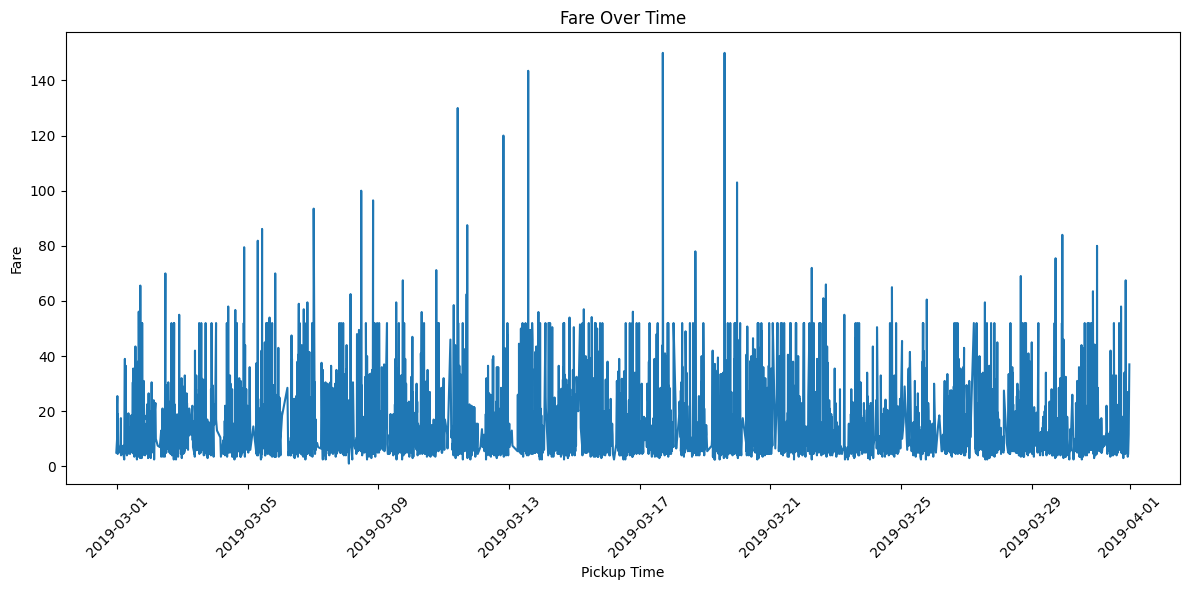

In [6]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


taxis = sns.load_dataset("taxis")

taxis["pickup"] = pd.to_datetime(taxis["pickup"])
taxis = taxis.sort_values("pickup")
plt.figure(figsize=(12, 6))
plt.plot(taxis["pickup"], taxis["fare"])
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.title("Fare Over Time")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**★ Bar Chart**

Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.

pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    58753.42
Queens       16382.06
Name: fare, dtype: float64


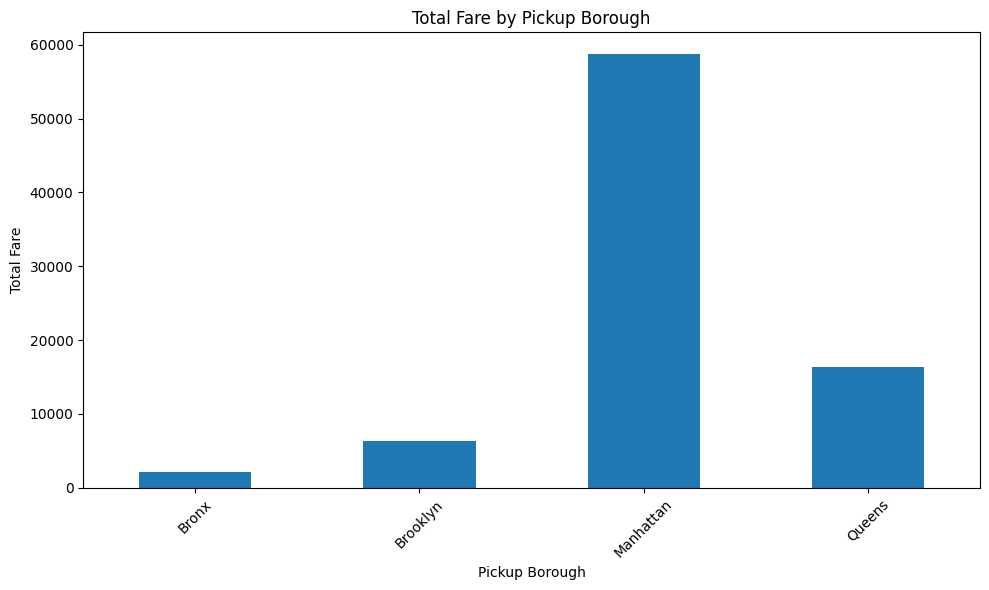

In [7]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


taxis = sns.load_dataset("taxis")

# Group by pickup_borough and calculate total fare
borough_fare = taxis.groupby("pickup_borough")["fare"].sum()

print(borough_fare)


plt.figure(figsize=(10, 6))
borough_fare.plot(kind="bar")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**★ Pie Chart**

Plot a pie chart showing the distribution of trips based on the payment method (credit card,
cash, etc.). Each slice should represent the count of trips for a specific payment method.

Trips by Payment Method:
payment
credit card    4577
cash           1812
Name: count, dtype: int64


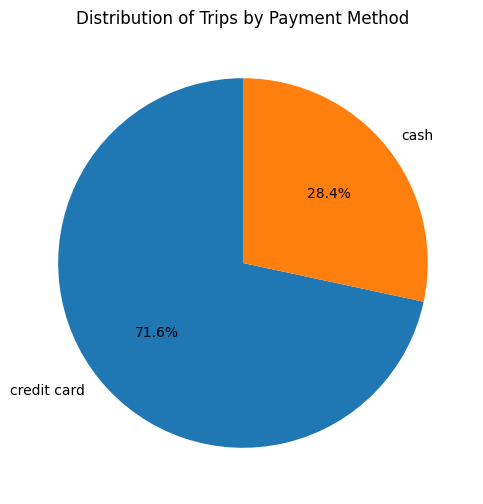

In [8]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


taxis = sns.load_dataset("taxis")
payment_counts = taxis["payment"].value_counts()
print("Trips by Payment Method:")
print(payment_counts)
plt.figure(figsize=(6, 6))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.show()

**★ Histogram**

Create a histogram to visualize the distribution of distance. Customize the number of bins for
better granularity and ensure the plot is easy to interpret.

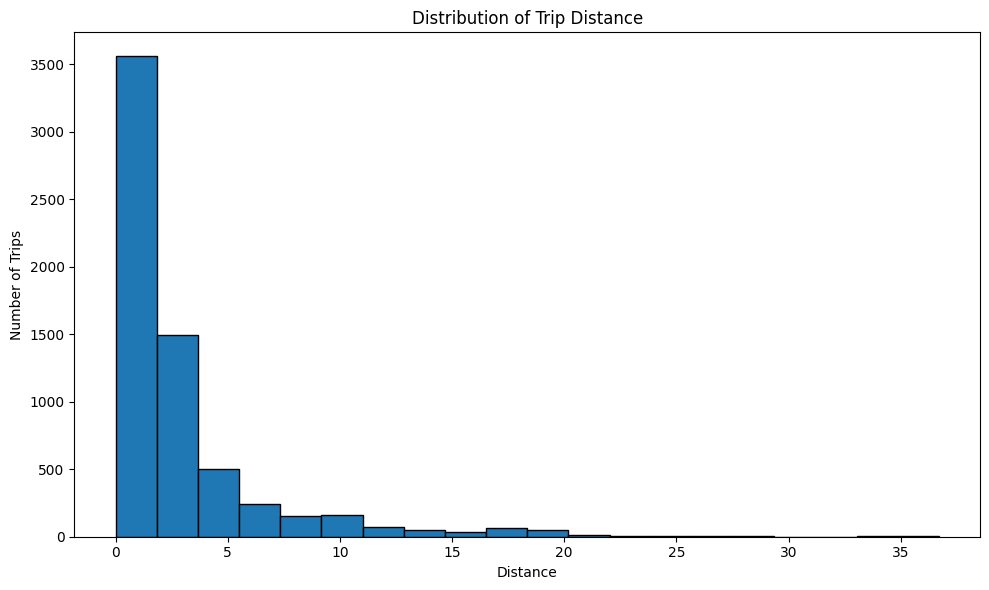

In [9]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

taxis = sns.load_dataset("taxis")


plt.figure(figsize=(10, 6))
plt.hist(
    taxis["distance"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Distance")

plt.tight_layout()
plt.show()

**★ Box Plot**

Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use
pickup_borough as the categorical axis and tip as the numeric axis.


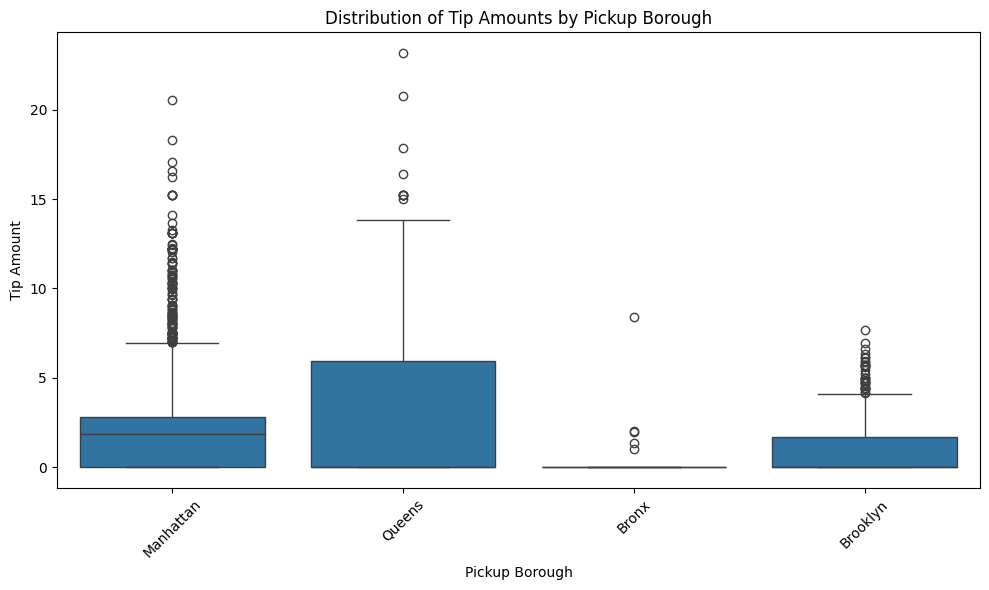

In [10]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

taxis = sns.load_dataset("taxis")
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="pickup_borough",
    y="tip",
    data=taxis
)

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Distribution of Tip Amounts by Pickup Borough")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Visualizations using Seaborn:**

**★ Count Plot**

Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should
represent the boroughs, and the y-axis should show the count of trips.


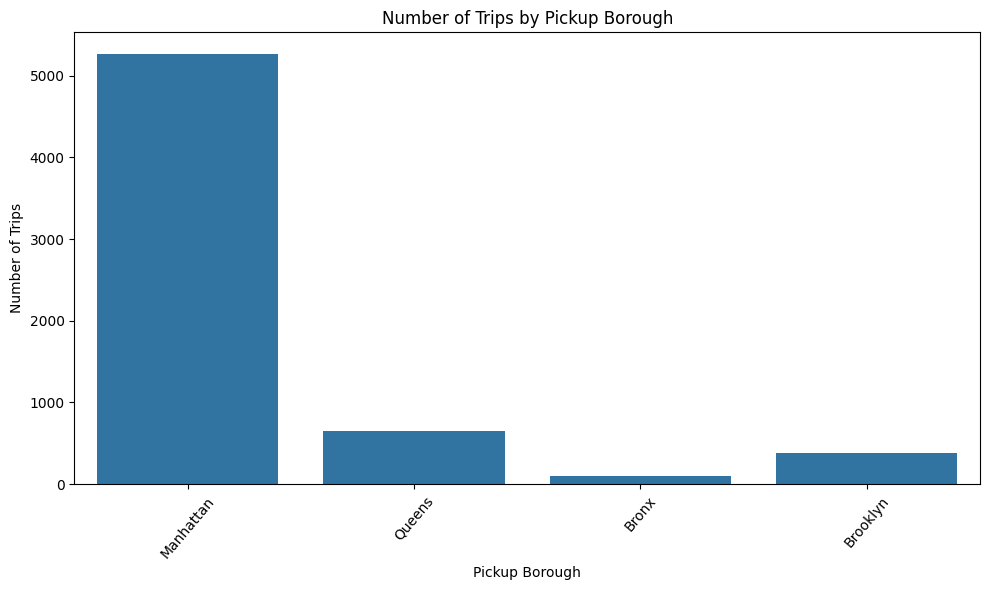

In [11]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


taxis = sns.load_dataset("taxis")


plt.figure(figsize=(10, 6))

sns.countplot(
    x="pickup_borough",
    data=taxis
)

plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")

plt.xticks(rotation=50)
plt.tight_layout()

plt.show()

**★ Scatter Plot**

Plot a scatterplot to show the relationship between distance and fare. Use distance on the
x-axis and fare on the y-axis to visualize any correlation. Color the points based on the
pickup_borough to differentiate the trips by their respective boroughs.

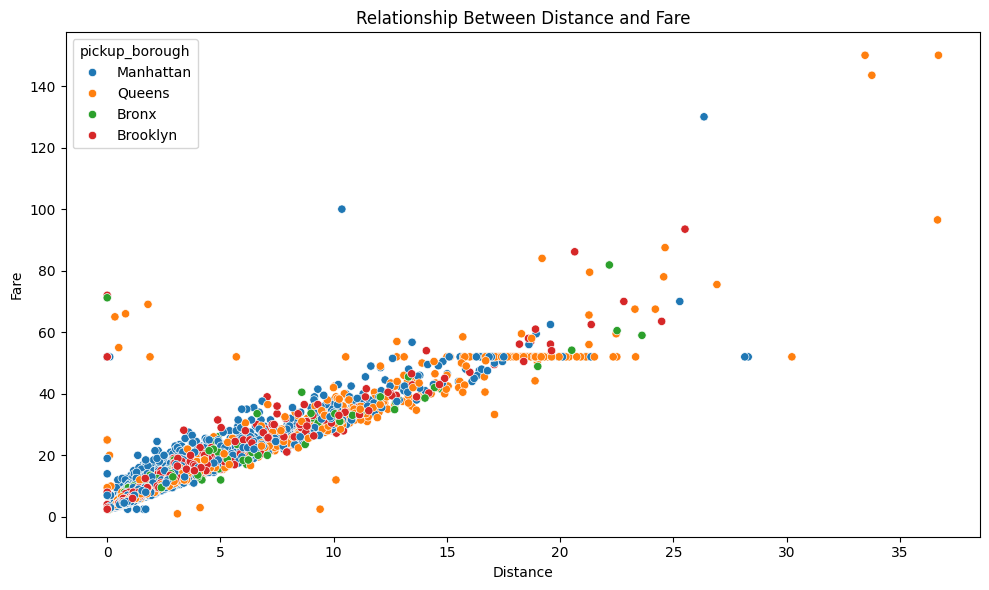

In [12]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


taxis = sns.load_dataset("taxis")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=taxis,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Relationship Between Distance and Fare")

plt.tight_layout()
plt.show()

**★ Heatmap**

Plot a heatmap to visualize the correlation between numerical variables such as distance, fare,
tip, tolls, and total. Use a correlation matrix to highlight the relationships.

Correlation Matrix:
          distance      fare       tip     tolls     total
distance  1.000000  0.920108  0.452589  0.635267  0.904676
fare      0.920108  1.000000  0.488612  0.609307  0.974358
tip       0.452589  0.488612  1.000000  0.413619  0.646186
tolls     0.635267  0.609307  0.413619  1.000000  0.683142
total     0.904676  0.974358  0.646186  0.683142  1.000000


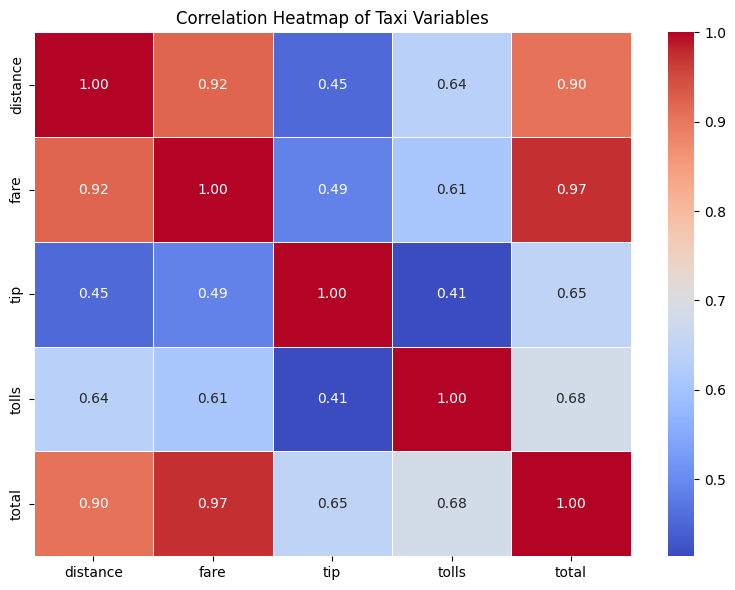

In [13]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


taxis = sns.load_dataset("taxis")
numerical_columns = ["distance", "fare", "tip", "tolls", "total"]


correlation_matrix = taxis[numerical_columns].corr()

print("Correlation Matrix:")
print(correlation_matrix)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Taxi Variables")
plt.tight_layout()

plt.show()

**★ Pair Plot**


Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total.
Color the data points according to the pickup_zone column. to compare how different zones
affect these variables.


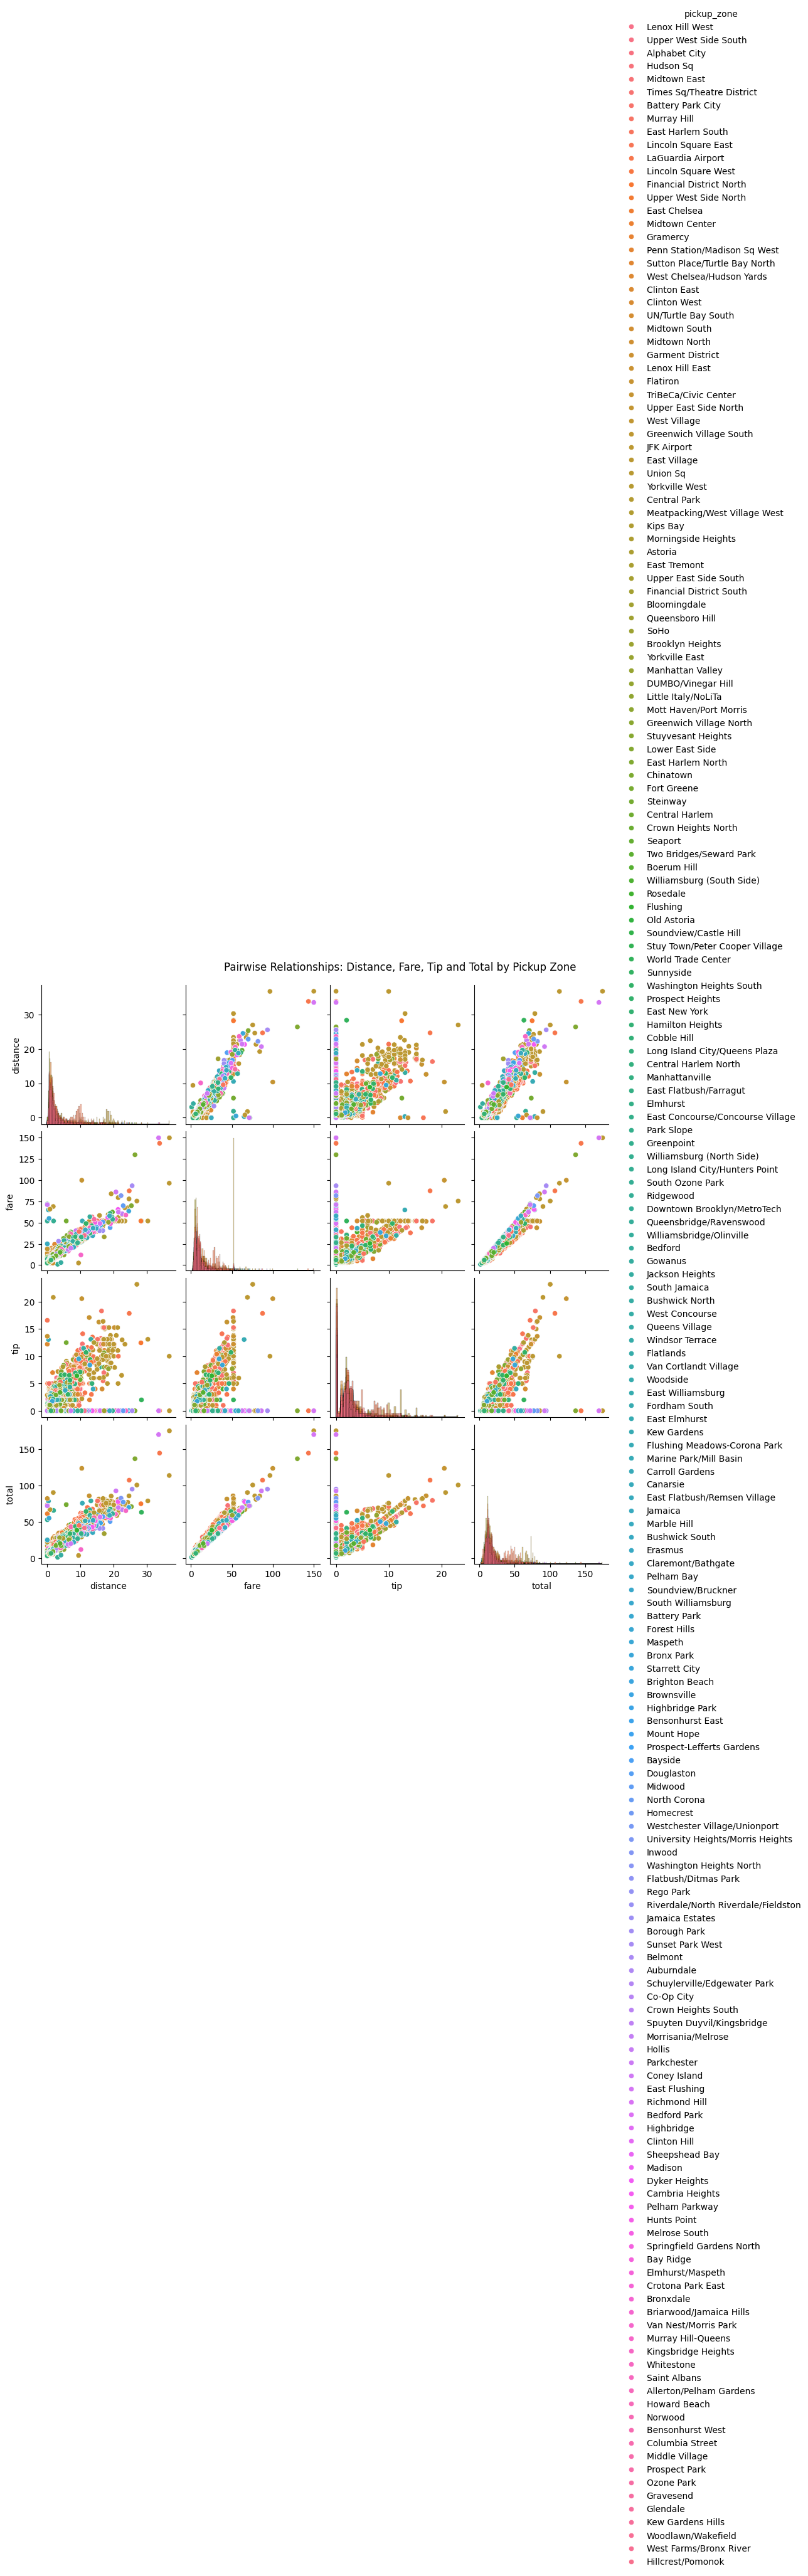

In [15]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


taxis = sns.load_dataset("taxis")

columns = ["distance", "fare", "tip", "total", "pickup_zone"]


sns.pairplot(
    taxis[columns],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.suptitle(
    "Pairwise Relationships: Distance, Fare, Tip and Total by Pickup Zone",
    y=1.02
)

plt.show()

**★ Violin Plot**

Plot a violin plot to show the distribution of fare for each payment method. Use the payment
method as the categorical axis and fare as the numeric axis to visualize its distribution.

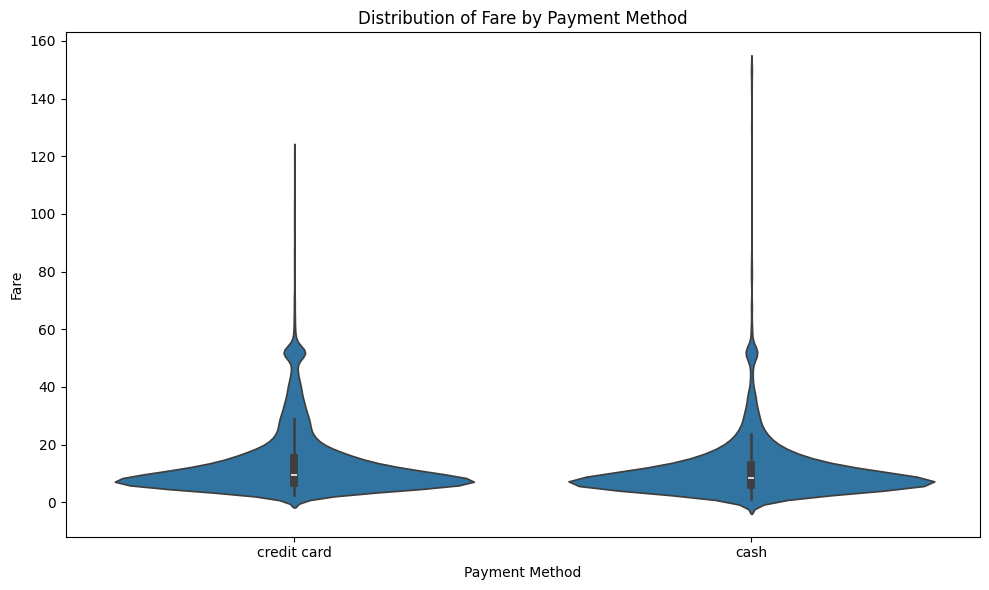

In [16]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

taxis = sns.load_dataset("taxis")

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=taxis,
    x="payment",
    y="fare"
)

plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Distribution of Fare by Payment Method")

plt.tight_layout()
plt.show()